# Phase 1: Basic forest fire = site percolation

A square forest. Each cell is a tree with probability **p** (the tree density), otherwise bare ground. We light every tree in the left column. At each step, every burning tree sets fire to its 4 side neighbours (up, down, left, right) that are trees, and then burns out. Fire never jumps diagonally and never crosses bare ground.

So the fire burns exactly the trees connected to the left edge by side-by-side chains. Whether it reaches the right edge is the classic **percolation** question. Theory says that in an infinitely large forest the answer flips sharply at **p_c ≈ 0.5927**: below it every fire dies out, above it fire can cross.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the code is cloned from GitHub if that repo exists; otherwise copy the project folder
# to Google Drive as MyDrive/forest_fire.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/forest_fire"):
    repo = "https://github.com/nhamhhung/forest-fire-spread.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/forest_fire"]).returncode == 0:
        os.chdir("/content/forest_fire")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/forest_fire")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from forest_fire import experiments as ex
from forest_fire.grid import make_forest, ignite_left_edge
from forest_fire.spread import run_fire
from forest_fire.plotting import plot_forest, plot_arrival, plot_spanning, plot_metric, animate_fire, gif_bytes

## 1. Three forests, one fire each
Top: the forest after the fire (green = survived, grey = burnt). Bottom: when each tree caught fire.

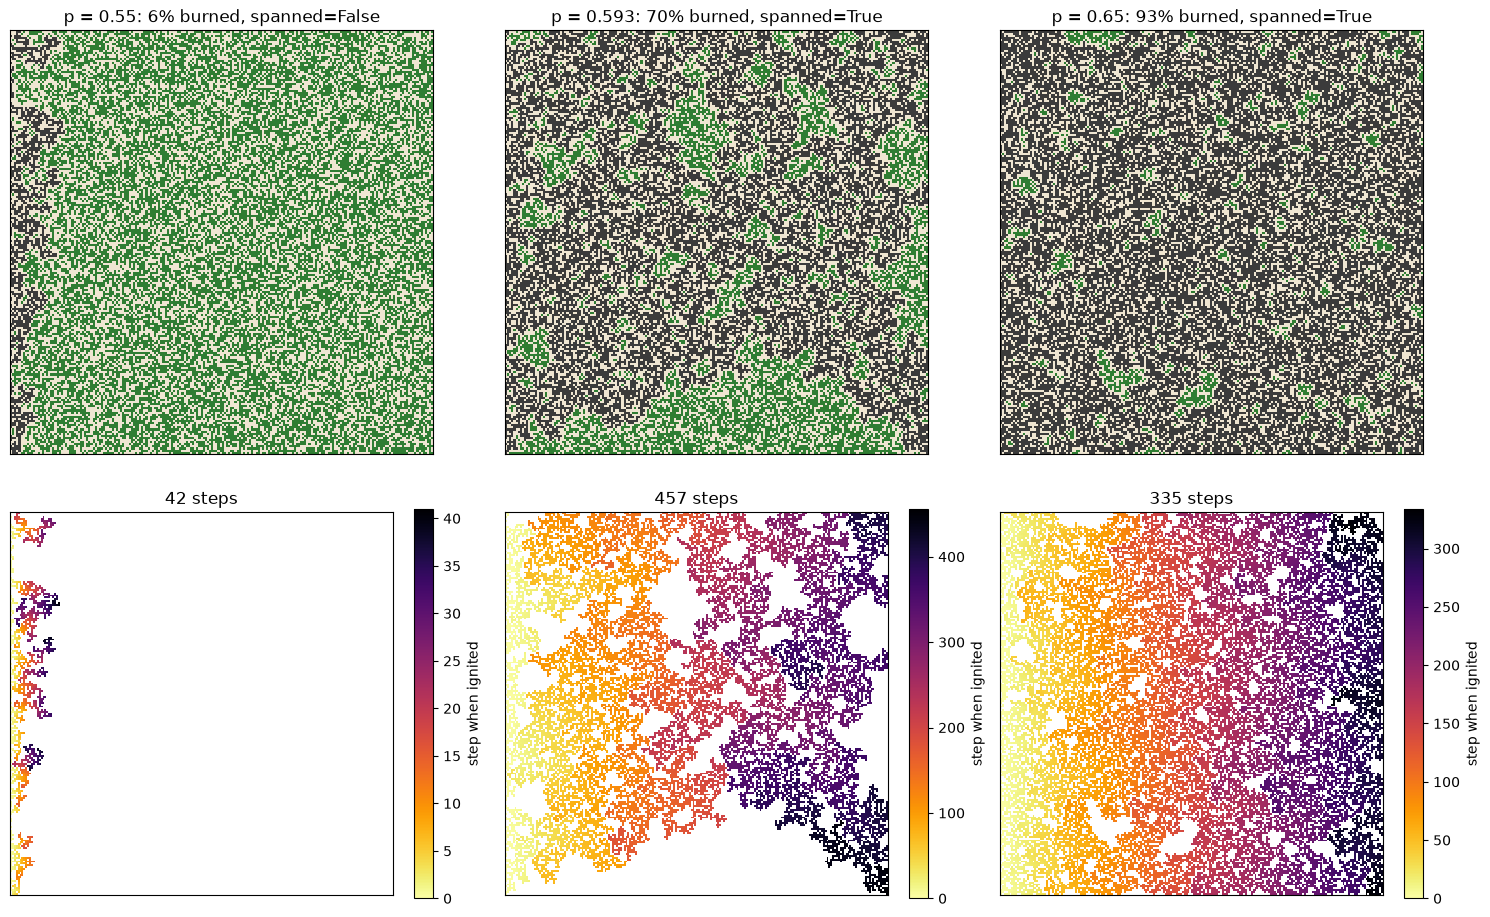

In [2]:
rng = np.random.default_rng(7)
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for k, p in enumerate([0.55, 0.593, 0.65]):
    forest = make_forest(200, p, rng)
    final, arrival, duration = run_fire(ignite_left_edge(forest))
    m = ex.fire_metrics(forest)
    plot_forest(final, ax=axes[0, k], title=f"p = {p}: {100*m['fraction_burned']:.0f}% burned, spanned={m['spanned']}")
    plot_arrival(arrival, ax=axes[1, k], title=f"{duration} steps")
plt.tight_layout(); plt.show()

* **p = 0.55:** the fire finds only small clusters touching the left edge and dies within a few dozen steps.
* **p = 0.593 (≈ p_c):** the burnt cluster is a ragged, branching shape full of holes, and the fire takes the longest to burn out, because its path winds.
* **p = 0.65:** the forest is so well connected that the fire sweeps across almost everything in a fairly straight front.

## 2. Watch a fire at the critical density

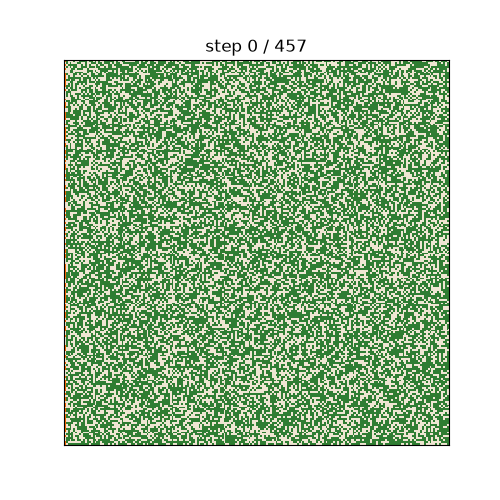

In [3]:
rng = np.random.default_rng(7); _ = make_forest(200, 0.55, rng)   # same forest as the middle panel above
forest = make_forest(200, 0.593, rng)
_, arrival, _ = run_fire(ignite_left_edge(forest))
anim = animate_fire(forest, arrival, n_frames=50); plt.close()
Image(data=gif_bytes(anim))

## 3. The switch from dying out to spreading
For each density we burn 100 random forests and record how often the fire reaches the far edge.

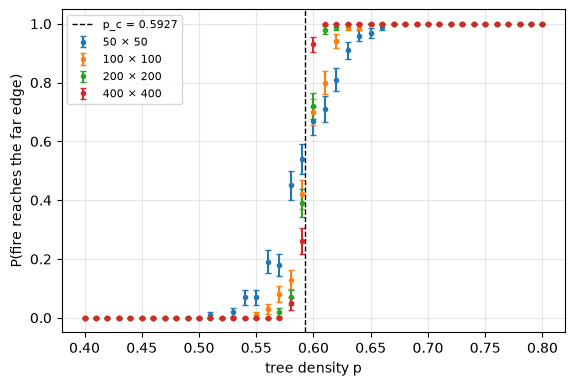

In [4]:
s = ex.Phase1Settings()
coarse = pd.concat([ex.density_sweep(n, s.densities, s.n_runs, s.seed) for n in s.sizes], ignore_index=True)
plot_spanning(coarse); plt.show()

## 4. Where exactly is the switch, and how sharp is it?
A fine sweep around p_c (200 forests per point), with a logistic step fitted to each size. **p50** is the density where half the fires cross; **width** is how gradual the switch is.

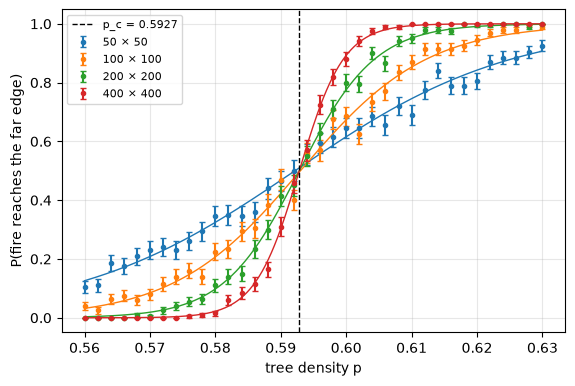

{'width_exponent': -0.7622238663946347, 'width_exponent_expected': -0.75}


,size,p50,p50_err,width,width_err
0,50,0.5922,0.0004,0.0166,0.0004
1,100,0.5930,0.0003,0.0097,0.0003
2,200,0.5928,0.0001,0.0058,0.0001
3,400,0.5928,0.0001,0.0034,0.0001


In [5]:
fine = pd.concat([ex.density_sweep(n, s.fine_densities, s.fine_runs, s.seed + 1) for n in s.sizes], ignore_index=True)
fits = pd.DataFrame([{"size": n, **ex.fit_transition(fine[fine["size"] == n])} for n in s.sizes])
plot_spanning(fine, fits); plt.show()
print(ex.finite_size_scaling(fits))
fits.round(4)

* **p50 ≈ 0.593 for every size**, matching the exact percolation threshold 0.5927.
* **The switch sharpens as the forest grows.** The width shrinks like L^(-0.76), close to the theoretical L^(-3/4) (ν = 4/3). In an infinite forest it would be a perfect jump.

## 5. How much burns, and for how long

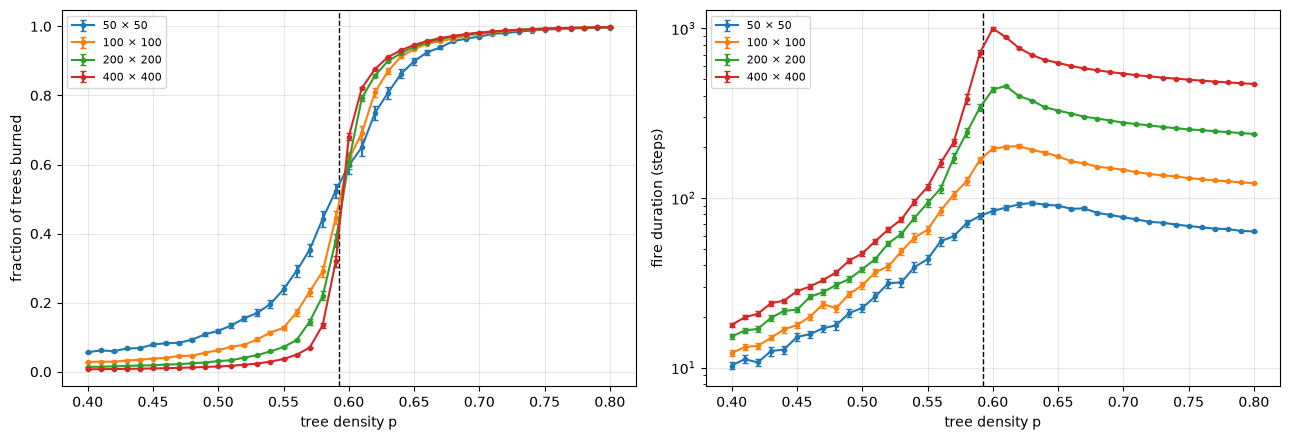

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_metric(coarse, "fraction_burned", "fraction of trees burned", ax=axes[0])
plot_metric(coarse, "duration", "fire duration (steps)", ax=axes[1], logy=True)
plt.tight_layout(); plt.show()

## Takeaways
* A forest's fate hinges on one number. Below about 59% tree cover, fires stay local no matter how big the forest is. Above it, a single fire can burn through the whole forest.
* Near the threshold fires burn **longest**, because the fire path is a long, winding chain. This "critical slowing down" is a fingerprint of the transition.
* Small changes in density near p_c cause huge changes in fire size. That makes the threshold the natural target for fire management (Phase 4). It is also why anything that shifts it, such as drought making fire spread more easily (Phases 2–3), matters so much.